<br>
<br>

# `#01: How a object detection model works that also predict a bounding box`

<br>
<br>

## ধাপ ০: Anchor বানানো

**কখন:** training শুরুর আগে, **একবারই**। পুরো training-এ একই anchor ব্যবহার হয়।

**কী লাগে:** শুধু তিনটা জিনিস, কোনো ছবি, network বা ground truth লাগে না:
- ছবির সাইজ (যেমন 640×640)
- feature map-গুলোর stride (যেমন 8, 16, 32)
- প্রতিটা stride-এ কোন সাইজের anchor (যেমন 16 আর 32 px, 64 আর 128 px ...)

**কী হয়:** প্রতিটা feature map-এর প্রতিটা ঘরের center-এ নির্দিষ্ট সাইজের box বসানো হয়।

**Output:** `anchors [P, 4]`, center form `(cx, cy, w, h)`, 0-1-এ normalized। 640 ছবিতে P = 16800।

**RetinaFace-এ:** `PriorBox(cfg, image_size).forward()`

**Inference-এ:** ছবির সাইজ বদলালে anchor আবার বানাতে হয়, কারণ grid-এর সাইজ ছবির ওপর নির্ভর করে।


**How to calcute stirde and feature map:**
ছবি          640 × 640 <br>
conv, s=2 →  320 × 320      মোট stride 2 <br>
conv, s=2 →  160 × 160      মোট stride 2×2 = 4 <br>
conv, s=2 →   80 × 80       মোট stride 8     ← feature map ১ (এখান থেকে নেওয়া হয়) <br>
conv, s=2 →   40 × 40       মোট stride 16    ← feature map ২ <br>
conv, s=2 →   20 × 20       মোট stride 32    ← feature map ৩ <br>


<br>
<br>


## ধাপ ১: Data লোড

**কখন:** প্রতিটা batch-এ

**কী হয়:**
1. ছবি পড়া হয়
2. Augmentation: random crop, flip, resize → 640 × 640
3. GT(Ground Truth) box-এর coordinate ছবির সাইজ দিয়ে ভাগ → 0 থেকে 1-এর মধ্যে

**Output ১: images**

```
images  [B, 3, 640, 640]
         │  │   └─ height, width
         │  └─ RGB channel
         └─ batch-এ কয়টা ছবি
```

**Output ২: targets (কাঁচা ground truth)**

প্রতিটা object-এর জন্য একটা সারি, প্রতিটা সারিতে ৫টা সংখ্যা:

```
[x1, y1, x2, y2, label]
 └──── box ────┘  └ class নম্বর
```

উদাহরণ (label 1 = মানুষ, 2 = গাড়ি):

```
ছবি ১: মানুষ + গাড়ি
targets[0] = [[0.45, 0.35, 0.62, 0.98, 1],
              [0.08, 0.48, 0.88, 0.92, 2]]     shape [2, 5]

ছবি ২: একটা গাড়ি
targets[1] = [[0.20, 0.40, 0.70, 0.85, 2]]     shape [1, 5]

ছবি ৩: ৫ জন মানুষ
targets[2] = ...                                shape [5, 5]
```

**কেন tensor না, list:** প্রতিটা ছবিতে object-এর সংখ্যা আলাদা, তাই shape `[2,5]`, `[1,5]`, `[5,5]` একসাথে এক tensor-এ রাখা যায় না।

<br>
<br>

## ধাপ ৩: Target বানানো (network ছাড়া)

**কখন:** প্রতিটা batch-এ, batch-এর **প্রতিটা ছবির জন্য আলাদা করে**

**কেন প্রতিবার:** Anchor একই থাকে, কিন্তু random crop-এর কারণে একই ছবির GT box প্রতি epoch-এ আলাদা জায়গায় পড়ে। তাই কোন anchor positive, সেটা প্রতিবার নতুন করে হিসাব করতে হয়।

**Input:**
- ধাপ ১-এর `targets` (এই ছবির GT তালিকা), যেমন `[2, 5]`
- ধাপ ০-এর `anchors [P, 4]`

নিচে খেলনা উদাহরণ: ২টা face (f0, f1), ৮টা anchor (a0 থেকে a7)।

### ১. IoU টেবিল

```python
overlaps = jaccard(truths, point_form(priors))      # [2, 8]
```

Anchor center form-এ থাকে, তাই আগে `point_form` দিয়ে corner form-এ আনা হয়। তারপর প্রতিটা face বনাম প্রতিটা anchor-এর IoU:

```
      a0    a1    a2     a3    a4    a5  a6  a7
f0  [0.60  0.75  0.346  0.29  0.00  0   0   0 ]
f1  [0.00  0.04  0.00   0.27  0.11  0   0   0 ]
```

### ২. প্রতিটা anchor-এর সেরা face (কলাম বরাবর)

```python
best_truth_overlap, best_truth_idx = overlaps.max(0)    # [8]
```

```
ovl = [0.60  0.75  0.346  0.29  0.11  0  0  0]     কত মিলেছে
idx = [0     0     0      0     1     0  0  0]     কোন face জিতেছে
```

প্রশ্ন: "এই anchor যদি কিছু শেখে, কোন face শিখবে?"

### ৩. প্রতিটা face-এর সেরা anchor (সারি বরাবর), জোর করে positive

```python
best_prior_overlap, best_prior_idx = overlaps.max(1)    # f0 → a1, f1 → a3
best_truth_overlap.index_fill_(0, best_prior_idx, 2)    # a1, a3 এর ovl = 2
for j in range(num_gt):
    best_truth_idx[best_prior_idx[j]] = j               # a3 এর idx = 1
```

```
ovl = [0.60  2     0.346  2     0.11  0  0  0]
idx = [0     0     0      1     1     0  0  0]
```

কেন: f1-এর সেরা IoU মাত্র 0.27। এটা না করলে threshold-এর কারণে f1 একটাও anchor পেত না, আর loop না থাকলে a3 ভুল করে f0 শিখত।

(সেরা IoU 0.2-এর নিচে হলে ওই face-কে জোর করে anchor দেওয়া হয় না, "hard gt" হিসেবে বাদ।)

### ৪. Label

```python
conf = labels[best_truth_idx]
conf[best_truth_overlap < 0.35] = 0
```

```
conf = [1  1  0  1  0  0  0  0]
```

a0, a1 → face 0, a3 → face 1, বাকি সব background। a2 (0.346) অল্পের জন্য বাদ।

### ৫. Encode

```python
matches = truths[best_truth_idx]           # প্রতিটা anchor-এর face-এর box
loc = encode(matches, priors, variances)   # [8, 4]
```

প্রতিটা anchor-এর সারিতে `[dx, dy, dw, dh]`: center কতটা সরবে, size কত গুণ হবে। যেমন a0 → `[1.25, 1.56, 0, 0.86]`। Background anchor-এর জন্যও হিসাব হয়, কিন্তু loss-এ ব্যবহার হয় না।

### Output (এটাই Andrew Ng-এর `y`)

```python
conf_t[idx] = conf     # class_target [B, P]      0 = background, 1, 2 ... = class
loc_t[idx]  = loc      # box_target   [B, P, 4]   সঠিক offset
```

`match()` কিছু return করে না। `MultiBoxLoss` খালি tensor বানিয়ে দেয়, `match()` ছবির `idx` নম্বর সারিতে সরাসরি লিখে দেয়।

**মনে রাখার কথা:**
- Network-এর output লাগে না, শুধু GT আর anchor
- Matching হয় IoU দিয়ে, class দিয়ে না
- 🔹 stride আর 🔸 feature map: এই ধাপে কোনোটাই নেই, ১৬৮০০টা anchor শুধু একটা লম্বা তালিকা
- **RetinaFace-এ:** `match()`, `MultiBoxLoss`-এর ভেতর থেকে প্রতিটা ছবির জন্য call হয়

<br>
<br>

## ধাপ ৪: Loss

**কখন:** প্রতিটা batch-এ

**Input:**
- ধাপ ২ (network) থেকে: `class_pred [B, P, C]`, `box_pred [B, P, 4]`
- ধাপ ৩ (`match`) থেকে: `class_target [B, P]`, `box_target [B, P, 4]`

এখানে প্রথমবার network-এর উত্তর আর সঠিক উত্তর মুখোমুখি হয়। দুটোই একই মাপের, n নম্বর সারি = n নম্বর anchor।

নিচে ধাপ ৩-এর খেলনা উদাহরণই চালিয়ে যাচ্ছি: ৮টা anchor, `conf_t = [1, 1, 0, 1, 0, 0, 0, 0]`। Network-এর prediction আমি বানিয়ে নিয়েছি, যেন training-এর মাঝামাঝি অবস্থা।

### ১. Positive mask

```python
pos = conf_t != 0
# [T, T, F, T, F, F, F, F]  → positive: a0, a1, a3 (N = 3)
```

এই mask দিয়েই ঠিক হয় কোন anchor কোন loss-এ যাবে।

### ২. Box loss (শুধু positive)

```python
pos_idx = pos.unsqueeze(-1).expand_as(loc_data)   # [B, P] → [B, P, 4]
loc_p = loc_data[pos_idx].view(-1, 4)             # network-এর offset, শুধু positive
loc_t = loc_t[pos_idx].view(-1, 4)                # সঠিক offset, শুধু positive
loss_l = F.smooth_l1_loss(loc_p, loc_t, reduction='sum')
```

`unsqueeze` + `expand` দিয়ে mask-কে ৪ কলামে ছড়ানো হয়, যাতে প্রতিটা positive anchor-এর ৪টা সংখ্যাই একসাথে বাছাই হয়।

**Smooth L1 কী:** প্রতিটা সংখ্যার পার্থক্য `x` নিয়ে:
```
|x| < 1  →  0.5 × x²     ছোট ভুল: আস্তে আস্তে শাস্তি, শূন্যের কাছে মসৃণ
|x| ≥ 1  →  |x| − 0.5    বড় ভুল: সরলরেখায় বাড়ে, বর্গ হয়ে বিস্ফোরিত হয় না
```

a0-এর উদাহরণ:
```
সঠিক   = [1.25, 1.56, 0.00, 0.86]
network = [1.00, 1.20, 0.30, 0.50]
পার্থক্য = [−0.25, −0.36, 0.30, −0.36]    সব ছোট → 0.5 × x²
loss    = 0.031 + 0.066 + 0.045 + 0.065 = 0.21
```

a3-এ network অনেক ভুল করেছে (পার্থক্য 1.47, 1.55), সেখানে loss বর্গ না হয়ে সরলরেখায় বাড়ে (1.47 − 0.5 = 0.97)। তিনটা positive মিলিয়ে `loss_l = 4.64`।

Background-এর box বাদ কেন: a5-এর তো কোনো face নেই, তার "সঠিক offset" বলে কিছু নেই। সেটা শেখালে network আবর্জনা শিখত।

### ৩. Class loss + hard negative mining

**ক. প্রতিটা anchor-এর cross entropy আলাদা করে**

```python
loss_c = log_sum_exp(batch_conf) - batch_conf.gather(1, conf_t.view(-1, 1))
```

এটা হাতে লেখা cross entropy: `−log(সঠিক class-এর সম্ভাবনা)`। Network যত নিশ্চিতভাবে ভুল বলে, loss তত বেশি।

```
anchor:     a0     a1     a2     a3     a4     a5     a6     a7
সঠিক:       face   face   bg     face   bg     bg     bg     bg
network     0.70   0.90   0.60   0.20   0.30   0.05   0.10   0.02
(face prob)
loss:       0.36   0.11   0.92   1.61   0.36   0.05   0.11   0.02
```

a2 দেখো: আসলে background, কিন্তু network 60% নিশ্চিত যে face। এটাই **hard negative**।

**খ. Negative-দের loss অনুযায়ী সাজানো**

```python
loss_c[pos] = 0                                # positive আপাতত বাদ, শুধু negative-দের rank
_, loss_idx = loss_c.sort(1, descending=True)
_, idx_rank = loss_idx.sort(1)                 # প্রতিটা anchor কত নম্বরে
```

```
negative-দের rank: a2 (0.92) > a4 (0.36) > a6 (0.11) > a5 (0.05) > a7 (0.02)
```

**গ. কয়টা negative নেবো**

```python
num_neg = torch.clamp(self.negpos_ratio * num_pos, max=pos.size(1) - 1)
neg = idx_rank < num_neg
```

RetinaFace-এ ratio 7, মানে 3 × 7 = 21টা। কিন্তু খেলনায় negative আছে মাত্র ৫টা, তাই বোঝার জন্য ধরো ratio 1, মানে ৩টা: **a2, a4, a6**। a5, a7 বাদ, কারণ network ওদের ইতিমধ্যে ঠিক বলছে, ওখান থেকে শেখার কিছু নেই।

Astronaut ছবিতে এর আসল প্রভাব দেখা যায়: ১০৭২০টা negative থেকে মাত্র ৩২ × ৭ = ২২৪টা।

**ঘ. Positive + বাছাই করা negative মিলিয়ে cross entropy**

```python
conf_p = conf_data[(pos_idx + neg_idx).gt(0)].view(-1, num_classes)
targets_weighted = conf_t[(pos + neg).gt(0)]
loss_c = F.cross_entropy(conf_p, targets_weighted, reduction='sum')
```

```
positive: a0 0.36 + a1 0.11 + a3 1.61 = 2.07
negative: a2 0.92 + a4 0.36 + a6 0.11 = 1.38
loss_c = 3.45
```

**কেন hard negative mining:** সব ১০৭২০টা negative নিলে তাদের loss-এর যোগফল ৩২টা positive-কে ডুবিয়ে দিত। Network শিখে ফেলত "সবকিছু background বলে দাও", তাতেই loss কমে যায়।

### ৪. Normalize

```python
N = max(num_pos.sum(), 1)      # 3
loss_l /= N                    # 4.64 / 3 = 1.55
loss_c /= N                    # 3.45 / 3 = 1.15
```

কেন: ১০টা face-ওয়ালা ছবিতে positive বেশি, তাই loss-এর যোগফলও বেশি হতো। N দিয়ে ভাগ করলে প্রতিটা ছবির loss একই মাপে আসে। `max(..., 1)` শূন্য দিয়ে ভাগ আটকায় (face নেই এমন ছবি)।

### ৫. Total

```python
loss = 2.0 * loss_l + loss_c + loss_landm     # train.py, loc_weight = 2
#    = 2 × 1.55 + 1.15 + ...  = 4.25 + landmark loss
```

Box loss-কে ২ গুণ গুরুত্ব, কারণ face খুঁজে পাওয়ার চেয়ে box ঠিক জায়গায় বসানো বেশি কঠিন।

**RetinaFace-এর বাড়তি অংশ (landmark loss):** box loss-এর হুবহু মতো, Smooth L1, শুধু ১০টা সংখ্যা। একটাই পার্থক্য: শুধু `conf_t > 0` (label 1) এমন anchor নেয়, landmark ছাড়া face (label −1) বাদ। আলাদা `N1` দিয়ে ভাগ।

**মনে রাখার কথা:**

| loss | কোন anchor | ফাংশন | মাপে |
|---|---|---|---|
| box | শুধু positive | Smooth L1 | offset কতটা ভুল |
| class | positive + hard negative | Cross entropy | face/background কতটা ভুল |
| landmark | শুধু landmark-ওয়ালা positive | Smooth L1 | landmark offset কতটা ভুল |

- 🔹 stride আর 🔸 feature map: এই ধাপে কোনোটাই নেই
- **RetinaFace-এ:** `MultiBoxLoss.forward()`

<br>
<br>

## ধাপ ৫: Backward আর update

**কখন:** প্রতিটা batch-এ।

`loss.backward()` gradient হিসাব করে, `optimizer.step()` network-এর weight বদলায়। তারপর পরের batch-এ আবার ধাপ ১ থেকে, কিন্তু ধাপ ০ আর হয় না।

## সময়ের হিসাবে এক নজরে

| কাজ | কখন | কতবার |
|---|---|---|
| Anchor বানানো | training শুরুর আগে | **একবার** |
| Data লোড + augmentation | প্রতি batch | প্রতি batch-এ একবার |
| Forward pass | প্রতি batch | প্রতি batch-এ একবার |
| Target বানানো (`match`) | প্রতি batch | batch-এর **প্রতিটা ছবির জন্য** একবার |
| Loss | প্রতি batch | প্রতি batch-এ একবার |
| Backward + update | প্রতি batch | প্রতি batch-এ একবার |

ধাপ ২ (network) আর ধাপ ৩ (target) একে অপরের ওপর নির্ভর করে না, দুটোই আলাদা আলাদা হিসাব হয়। ধাপ ৪-এ এসে প্রথমবার দুটো মুখোমুখি হয়: network কী বলল বনাম কী বলা উচিত ছিল।

<br>
<br>
<br>


# `# Step-0: Let's Build an Anchor at the start`


<br>
<br>
<br>

In [4]:

import torch 
a = torch.tensor(data=[[1,2,3,4,5],
                       [6,7,8,9,10]])
torch.clamp(a,min=3,max=7)


tensor([[3, 3, 3, 4, 5],
        [6, 7, 7, 7, 7]])

Feature maps:  [[64, 64], [32, 32], [16, 16]]
Priors Shape:  torch.Size([10752, 4])
Feature maps:  [[64, 64], [32, 32], [16, 16]]
Priors Shape:  torch.Size([10752, 4])


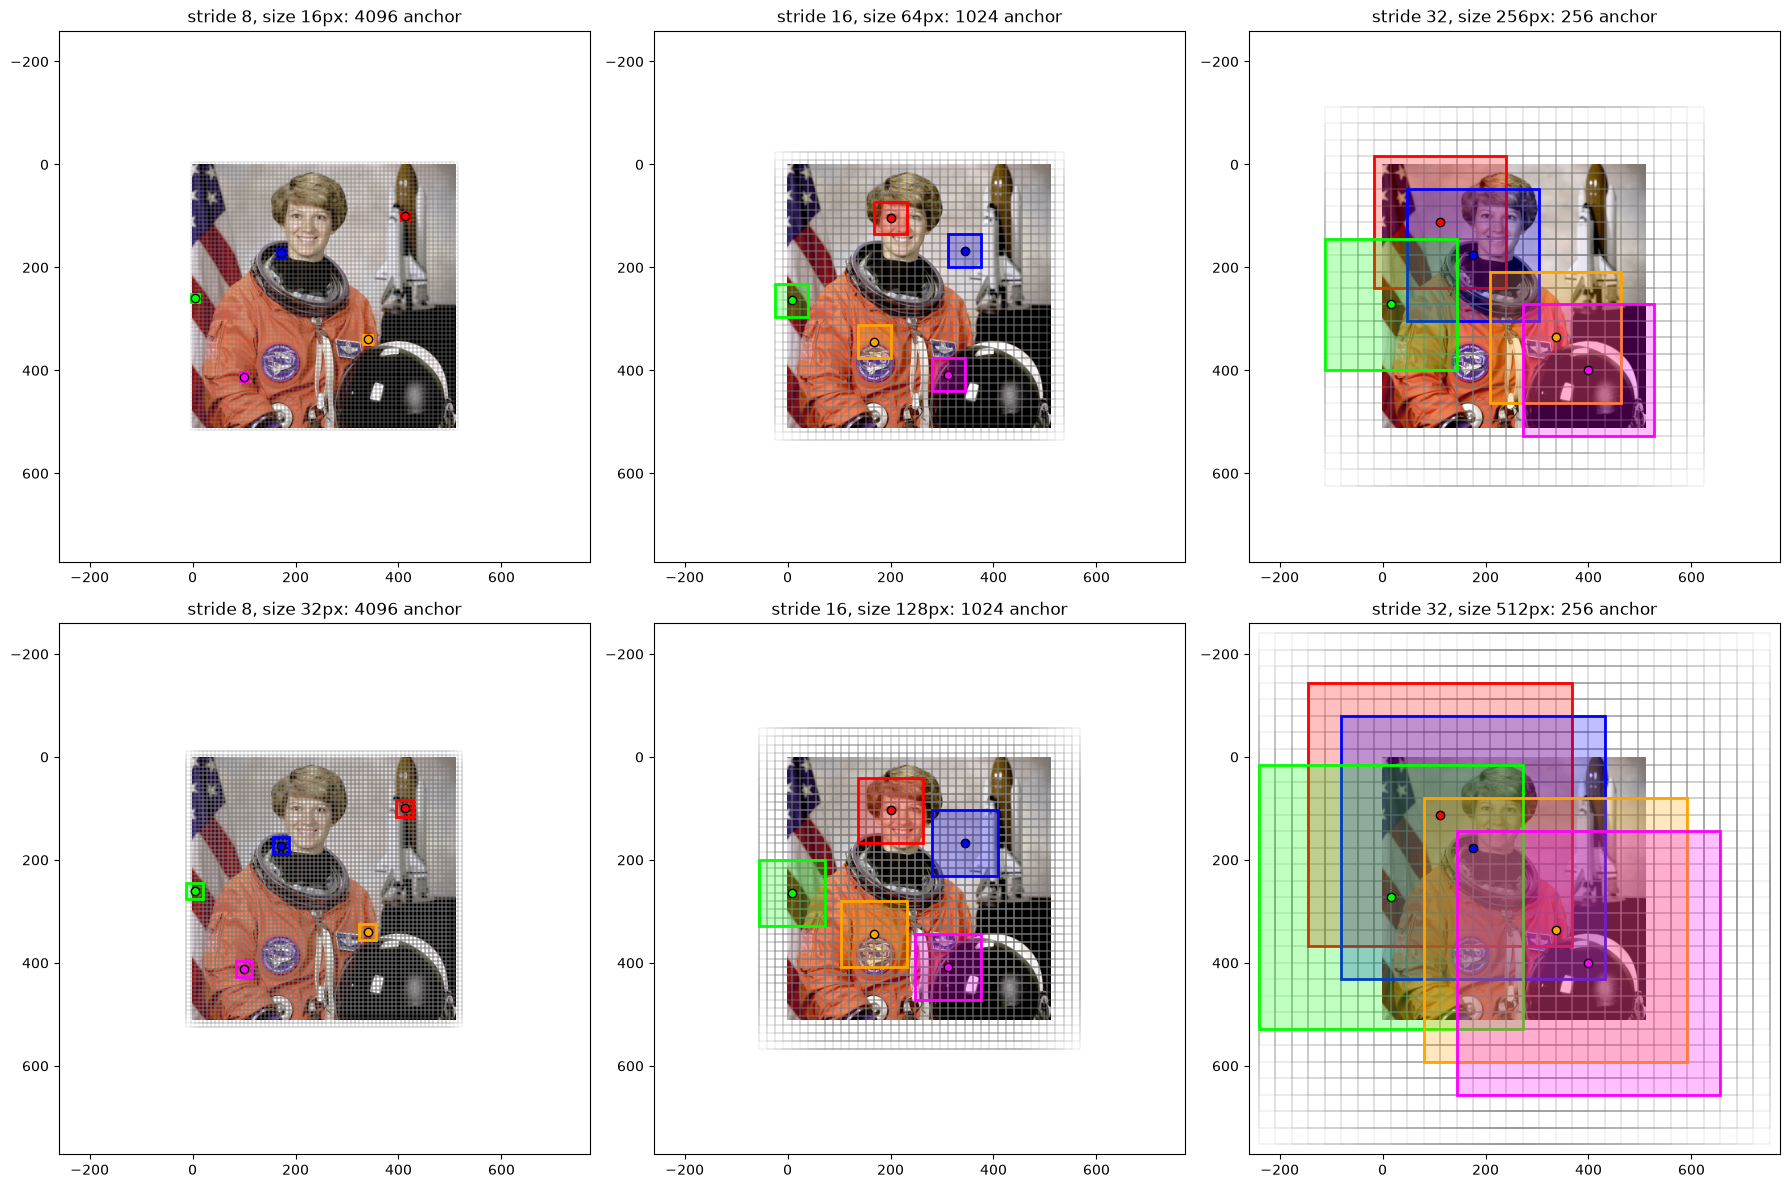

In [ ]:
#
# Source: https://github.com/biubug6/Pytorch_Retinaface (layers/prior_box.py)
# Copyright (c) 2019 Pytorch_Retinaface authors. MIT License, see LICENSE.MIT
# Modified by loopface authors. Copyright (c) 2026 Yasin Arafat. MIT License, see LICENSE
#

import torch
import numpy as np
from math import ceil
from itertools import product as product


class PriorBox(object):
    def __init__(self, cfg, image_size=None, phase='train'):
        super(PriorBox, self).__init__()
        self.min_sizes = cfg['min_sizes']
        self.steps = cfg['steps']
        self.clip = cfg['clip']
        self.image_size = image_size
        self.feature_maps = [[ceil(self.image_size[0]/step), ceil(self.image_size[1]/step)] for step in self.steps]
        self.name = "s"

    def forward(self):
        anchors = []
        for k, f in enumerate(self.feature_maps):
            min_sizes = self.min_sizes[k]
            for i, j in product(range(f[0]), range(f[1])):
                for min_size in min_sizes:
                    s_kx = min_size / self.image_size[1]
                    s_ky = min_size / self.image_size[0]
                    dense_cx = [x * self.steps[k] / self.image_size[1] for x in [j + 0.5]]
                    dense_cy = [y * self.steps[k] / self.image_size[0] for y in [i + 0.5]]
                    for cy, cx in product(dense_cy, dense_cx):
                        anchors += [cx, cy, s_kx, s_ky]

        # back to torch land
        output = torch.Tensor(anchors).view(-1, 4)
        if self.clip:
            output.clamp_(max=1, min=0)
        return output
    
    
from skimage import data 
img = data.astronaut()

# if our backbone is like this then:
""" 
ছবি          640 × 640 <br>
conv, s=2 →  320 × 320      মোট stride 2 <br>
conv, s=2 →  160 × 160      মোট stride 2×2 = 4 <br>
conv, s=2 →   80 × 80       মোট stride 8     ← feature map ১ (এখান থেকে নেওয়া হয়) <br>
conv, s=2 →   40 × 40       মোট stride 16    ← feature map ২ <br>
conv, s=2 →   20 × 20       মোট stride 32    ← feature map ৩ <br>
"""
""" 
stride 8  → [16, 32]       (= 2×8, 4×8)
stride 16 → [64, 128]      (= 4×16, 8×16)
stride 32 → [256, 512]     (= 8×32, 16×32)
"""
cfg = {
    'min_sizes':[[16,32],[64,128],[256,512]],
    'steps':[8,16,32],
    'clip':False
}
b = PriorBox(cfg=cfg,image_size=img.shape)
anchors = b.forward()

print("Feature maps: ",b.feature_maps)
print("Priors Shape: ",anchors.shape)
    
    
    #
# Source: https://github.com/biubug6/Pytorch_Retinaface (layers/prior_box.py)
# Copyright (c) 2019 Pytorch_Retinaface authors. MIT License, see LICENSE.MIT
# Modified by loopface authors. Copyright (c) 2026 Yasin Arafat. MIT License, see LICENSE
#

import torch
import numpy as np
from math import ceil
from itertools import product as product


class PriorBox(object):
    def __init__(self, cfg, image_size=None, phase='train'):
        super(PriorBox, self).__init__()
        self.min_sizes = cfg['min_sizes']
        self.steps = cfg['steps']
        self.clip = cfg['clip']
        self.image_size = image_size
        self.feature_maps = [[ceil(self.image_size[0]/step), ceil(self.image_size[1]/step)] for step in self.steps]
        self.name = "s"

    def forward(self):
        anchors = []
        for k, f in enumerate(self.feature_maps):
            min_sizes = self.min_sizes[k]
            for i, j in product(range(f[0]), range(f[1])):
                for min_size in min_sizes:
                    s_kx = min_size / self.image_size[1]
                    s_ky = min_size / self.image_size[0]
                    dense_cx = [x * self.steps[k] / self.image_size[1] for x in [j + 0.5]]
                    dense_cy = [y * self.steps[k] / self.image_size[0] for y in [i + 0.5]]
                    for cy, cx in product(dense_cy, dense_cx):
                        anchors += [cx, cy, s_kx, s_ky]

        # back to torch land
        output = torch.Tensor(anchors).view(-1, 4)
        if self.clip:
            output.clamp_(max=1, min=0)
        return output
    
    
from skimage import data 
img = data.astronaut()

# if our backbone is like this then:
""" 
ছবি          640 × 640 <br>
conv, s=2 →  320 × 320      মোট stride 2 <br>
conv, s=2 →  160 × 160      মোট stride 2×2 = 4 <br>
conv, s=2 →   80 × 80       মোট stride 8     ← feature map ১ (এখান থেকে নেওয়া হয়) <br>
conv, s=2 →   40 × 40       মোট stride 16    ← feature map ২ <br>
conv, s=2 →   20 × 20       মোট stride 32    ← feature map ৩ <br>
"""
""" 
stride 8  → [16, 32]       (= 2×8, 4×8)
stride 16 → [64, 128]      (= 4×16, 8×16)
stride 32 → [256, 512]     (= 8×32, 16×32)
"""
cfg = {
    'min_sizes':[[16,32],[64,128],[256,512]],
    'steps':[8,16,32],
    'clip':False
}
b = PriorBox(cfg=cfg,image_size=img.shape)
anchors = b.forward()

print("Feature maps: ",b.feature_maps)

# (cx, cy, w, h)
# cx -> centre x point
# cy -> centre y point
# w -> width
# h -> height
print("Priors Shape: ",anchors.shape)
    

# ================== vizualize anchors ==================
""" 
Fun fact.. here ther are almost 10752 boxes in a single image. Based on our 
min_size = [[16, 32], [64, 128], [256, 512]], we make total 10752 boxes. As, there 
are so many boxes we color up some boxes to understand actually there are boxes.
"""
import matplotlib.pyplot as plt
from matplotlib.collections import PatchCollection

a = anchors * 512
starts = [0, 8192, 10240, 10752]
pick_colors = ['red', 'blue', 'lime', 'orange', 'magenta']
fig, axes = plt.subplots(2, 3, figsize=(18, 12))

for k in range(3):                               
    part = a[starts[k]:starts[k+1]]
    for s in range(2):                                
        ax = axes[s, k]
        sub = part[s::2]                               
        ax.imshow(img)

        boxes = [plt.Rectangle((cx-w/2, cy-h/2), w, h) for cx, cy, w, h in sub.tolist()]
        ax.add_collection(PatchCollection(boxes, fc='none', ec='gray', lw=0.3, alpha=0.4))

       
        n = len(sub)
        for i, c in zip([n//5, n//3, n//2, 2*n//3, 4*n//5], pick_colors):
            cx, cy, w, h = sub[i].tolist()
            ax.add_patch(plt.Rectangle((cx-w/2, cy-h/2), w, h, fc=c, alpha=0.25))
            ax.add_patch(plt.Rectangle((cx-w/2, cy-h/2), w, h, fill=False, ec=c, lw=2))
            ax.plot(cx, cy, 'o', c=c, ms=6, mec='black')

        ax.set_title(f"stride {cfg['steps'][k]}, size {int(sub[0,2])}px: {n} anchor")
        ax.set_xlim(-260, 772); ax.set_ylim(772, -260)
plt.tight_layout()
plt.show()
    

<br>
<br>


# `Step:01 Make Target Without Network`

<br>
<br>

positive anchor: 32 / 10752
decode করা landmark (pixel), প্রথম anchor: [[200.0, 102.0], [247.0, 103.0], [220.0, 125.0], [199.0, 143.0], [240.0, 144.0]]


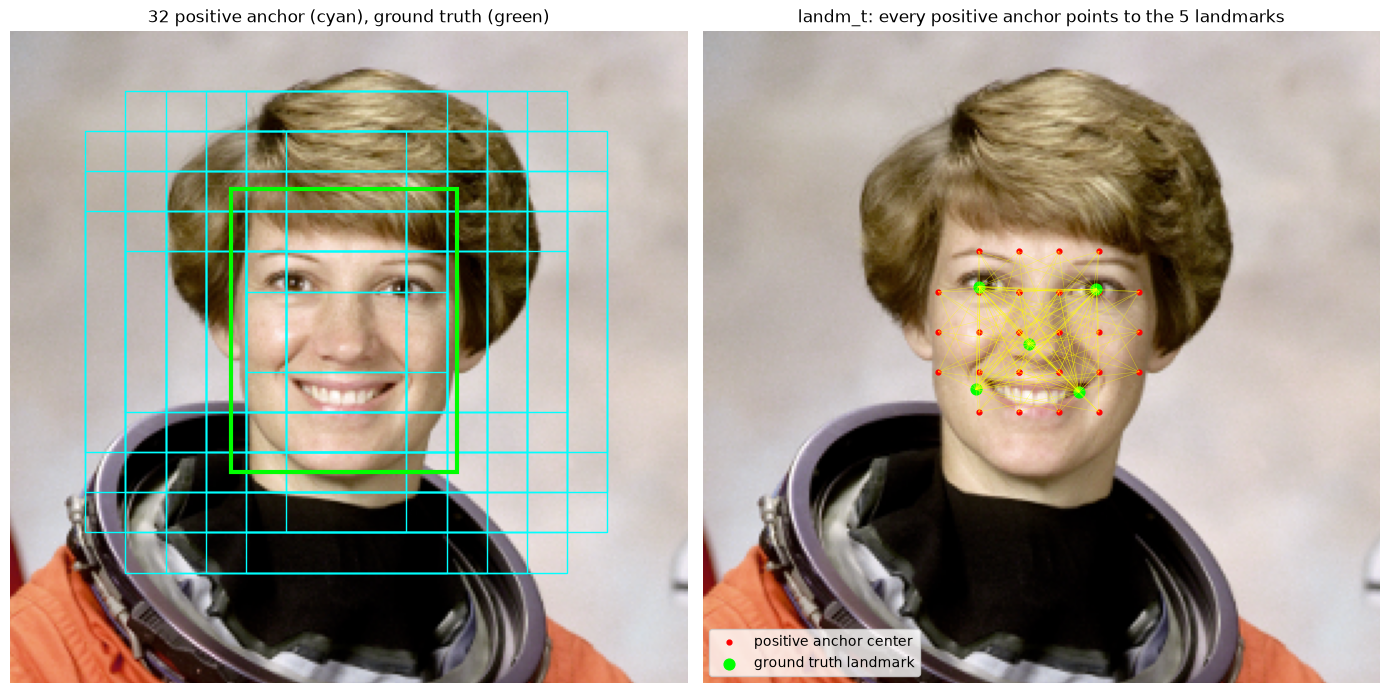

In [19]:
import torch 
import numpy as np 


def intersect(box_a, box_b):
    """ We resize both tensors to [A,B,2] without new malloc:
    [A,2] -> [A,1,2] -> [A,B,2]
    [B,2] -> [1,B,2] -> [A,B,2]
    Then we compute the area of intersect between box_a and box_b.
    Args:
      box_a: (tensor) bounding boxes, Shape: [A,4].
      box_b: (tensor) bounding boxes, Shape: [B,4].
    Return:
      (tensor) intersection area, Shape: [A,B].
    """
    # Input: A[[10,10,50,50]] B[[35,20,80,65]]->size(1,4)
    A = box_a.size(0) #1
    B = box_b.size(0) #1
    
    # torch.min -> [min(50,80), min(50,65)] = [[[50, 50]]]
    max_xy = torch.min(# [50,50] -> [[[50,50]]]  #(1,1,2) -> (pointA,pointB,total_2_point) -> 3D
                       box_a[:, 2:].unsqueeze(1).expand(A, B, 2),
                       box_b[:, 2:].unsqueeze(0).expand(A, B, 2))
    
    # torch.max -> [max(10,35), max(10,20)] = [[[35, 20]]]
    min_xy = torch.max( # [10,10] ->[[[10,10]]] # (1,1,2)
                       box_a[:, :2].unsqueeze(1).expand(A, B, 2),
                       box_b[:, :2].unsqueeze(0).expand(A, B, 2))
    
    # max_xy - min_xy = [50-35, 50-20] = [[[15, 30]]]
    # if any ans <0 then, that will be zero
    inter = torch.clamp((max_xy - min_xy), min=0)
    # [[15]]*[[30]] = [[450]] -> shape (1,1)
    return inter[:, :, 0] * inter[:, :, 1]


# orginal jaccard:
def iou_tensor(box_a, box_b):
    """Compute the box_iou_tensor overlap of two sets of boxes.  The box_iou_tensor overlap
    is simply the intersection over union of two boxes.  Here we operate on
    ground truth boxes and default boxes.
    E.g.:
        A ∩ B / A ∪ B = A ∩ B / (area(A) + area(B) - A ∩ B)
    Args:
        box_a: (tensor) Ground truth bounding boxes, Shape: [num_objects,4]
        box_b: (tensor) Prior boxes from priorbox layers, Shape: [num_priors,4]
    Return:
        box_iou_tensor overlap: (tensor) Shape: [box_a.size(0), box_b.size(0)]
    """
    inter = intersect(box_a, box_b)
    
    
    area_a = ((box_a[:, 2]-box_a[:, 0]) *
              (box_a[:, 3]-box_a[:, 1])).unsqueeze(1).expand_as(inter)  # [A,B]
    area_b = ((box_b[:, 2]-box_b[:, 0]) *
              (box_b[:, 3]-box_b[:, 1])).unsqueeze(0).expand_as(inter)  # [A,B]
    union = area_a + area_b - inter
    # output: 2 dim
    return inter / union  # [A,B]


def point_form(boxes):
    """ Convert prior_boxes to (xmin, ymin, xmax, ymax)
    representation for comparison to point form ground truth data.
    Args:
        boxes: (tensor) center-size default boxes from priorbox layers.
    Return:
        boxes: (tensor) Converted xmin, ymin, xmax, ymax form of boxes.
    """
    return torch.cat((boxes[:, :2] - boxes[:, 2:]/2,     # xmin, ymin
                     boxes[:, :2] + boxes[:, 2:]/2), 1)  # xmax, ymax


def center_size(boxes):
    """ Convert prior_boxes to (cx, cy, w, h)
    representation for comparison to center-size form ground truth data.
    Args:
        boxes: (tensor) point_form boxes
    Return:
        boxes: (tensor) Converted xmin, ymin, xmax, ymax form of boxes.
    """
    return torch.cat((boxes[:, 2:] + boxes[:, :2])/2,  # cx, cy
                     boxes[:, 2:] - boxes[:, :2], 1)  # w, h

def encode(matched, priors, variances):
    """Encode the variances from the priorbox layers into the ground truth boxes
    we have matched (based on jaccard overlap) with the prior boxes.
    Args:
        matched: (tensor) Coords of ground truth for each prior in point-form
            Shape: [num_priors, 4].
        priors: (tensor) Prior boxes in center-offset form
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        encoded boxes (tensor), Shape: [num_priors, 4]
    """

    # dist b/t match center and prior's center
    g_cxcy = (matched[:, :2] + matched[:, 2:])/2 - priors[:, :2]
    # encode variance
    g_cxcy /= (variances[0] * priors[:, 2:])
    # match wh / prior wh
    g_wh = (matched[:, 2:] - matched[:, :2]) / priors[:, 2:]
    g_wh = torch.log(g_wh) / variances[1]
    # return target for smooth_l1_loss
    return torch.cat([g_cxcy, g_wh], 1)  # [num_priors,4]

def encode_landm(matched, priors, variances):
    """Encode the variances from the priorbox layers into the ground truth boxes
    we have matched (based on jaccard overlap) with the prior boxes.
    Args:
        matched: (tensor) Coords of ground truth for each prior in point-form
            Shape: [num_priors, 10].
        priors: (tensor) Prior boxes in center-offset form
            Shape: [num_priors,4].
        variances: (list[float]) Variances of priorboxes
    Return:
        encoded landm (tensor), Shape: [num_priors, 10]
    """

    # dist b/t match center and prior's center
    matched = torch.reshape(matched, (matched.size(0), 5, 2))
    priors_cx = priors[:, 0].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_cy = priors[:, 1].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_w = priors[:, 2].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors_h = priors[:, 3].unsqueeze(1).expand(matched.size(0), 5).unsqueeze(2)
    priors = torch.cat([priors_cx, priors_cy, priors_w, priors_h], dim=2)
    g_cxcy = matched[:, :, :2] - priors[:, :, :2]
    # encode variance
    g_cxcy /= (variances[0] * priors[:, :, 2:])
    # g_cxcy /= priors[:, :, 2:]
    g_cxcy = g_cxcy.reshape(g_cxcy.size(0), -1)
    # return target for smooth_l1_loss
    return g_cxcy

def match(threshold, truths, priors, variances, labels, landms, loc_t, conf_t, landm_t, idx):
    """Match each prior box with the ground truth box of the highest iou
    overlap, encode the bounding boxes, then return the matched indices
    corresponding to both confidence and location preds.
    Args:
        threshold: (float) The overlap threshold used when mathing boxes.
        truths: (tensor) Ground truth boxes, Shape: [num_obj, 4].
        priors: (tensor) Prior boxes from priorbox layers, Shape: [n_priors,4].
        variances: (tensor) Variances corresponding to each prior coord,
            Shape: [num_priors, 4].
        labels: (tensor) All the class labels for the image, Shape: [num_obj].
        landms: (tensor) Ground truth landms, Shape [num_obj, 10].
        loc_t: (tensor) Tensor to be filled w/ endcoded location targets.
        conf_t: (tensor) Tensor to be filled w/ matched indices for conf preds.
        landm_t: (tensor) Tensor to be filled w/ endcoded landm targets.
        idx: (int) current batch index
    Return:
        The matched indices corresponding to 1)location 2)confidence 3)landm preds.
    """
    # truths = two face:
    # anchor = 8 boxes.
    #"""
    #overlaps  (shape [2, 8])
    #          dim 1 (anchor) →
    #              a0    a1    a2    a3    a4    a5  a6  a7
    #dim 0  f0  [ 0.60  0.75  0.35  0.29  0.00  0   0   0 ]
    #(face) f1  [ 0.00  0.04  0.00  0.27  0.11  0   0   0 ]
    #↓
    #"""
    overlaps = iou_tensor(
        truths,
        # (cx,cy,w,h) -> ((x1,y1),(x2,y2))
        point_form(priors)
    )

    # (Bipartite Matching)
    # [1,num_objects] best prior for each ground truth
    #  [[0.75], [0.27]] <-> Index([0], [1])
    # dim=1 means the second dimension, which is the number of columns in the tensor.
    best_prior_overlap, best_prior_idx = overlaps.max(1, keepdim=True)

    # ignore hard gt
    # if prior iou value < 0.2 then ignore: 
    valid_gt_idx = best_prior_overlap[:, 0] >= 0.2
    # [0.75(a1), 0.27(a3)] both are valid, so valid_gt_idx = [True, False]
    best_prior_idx_filter = best_prior_idx[valid_gt_idx, :]
    if best_prior_idx_filter.shape[0] <= 0:
        loc_t[idx] = 0
        conf_t[idx] = 0
        return

    # [1,num_priors] best ground truth for each prior, dim=0 row wise,
    #  best_truth_overlap = [0.75, 0.27, 0.35, 0.29, 0.11, 0, 0, 0]
    #  best_truth_idx = [0, 0, 0, 0, 1, 0, 0, 0]: 0-> face zero, 1-> face one
    best_truth_overlap, best_truth_idx = overlaps.max(0, keepdim=True)
    best_truth_idx.squeeze_(0)
    best_truth_overlap.squeeze_(0)
    best_prior_idx.squeeze_(1)
    best_prior_idx_filter.squeeze_(1)
    best_prior_overlap.squeeze_(1)

    # replace the value:  [0.75(a1), 0.27(a3)] -> [2, 2] 
    best_truth_overlap.index_fill_(0, best_prior_idx_filter, 2)  # ensure best prior

    # TODO refactor: index  best_prior_idx with long tensor
    # ensure every gt matches with its prior of max overlap
    #  best_truth_idx = [0, 0, 0, 0, 1, 0, 0, 0] modify this into:
    #  [0, 0, 0, 1, 1, 0, 0, 0] cause best_prior_idx for face-1 is anchor-3
    for j in range(best_prior_idx.size(0)):    
        best_truth_idx[best_prior_idx[j]] = j

    # find the matched ground truth.
    matches = truths[best_truth_idx]           
    conf = labels[best_truth_idx]   

    # best_truth_overlap[0.6,2,0.35,2,0.11,0,0,0]
    # IoU <= 0.35 identify as background, so set conf = 0 
    conf[best_truth_overlap < threshold] = 0  

    # box offset of each anchor to match the ground truth.
    # return [dx(from center how must shift left or right),dy(up down),dw(zoom width),dh(zoom height)] 
    # It's calculate for all priors, but only positive anchors will be used in loss function(BoxLoss).
    loc = encode(matches, priors, variances)

    # We have  5 landmarks in each face, for the positive anchors, we calucate how much we need 
    # to shift so that we can close to the 5 landsmarks. And this goes into BoxLoss funtion.
    # output: shape [P,10] -> 5 points.(x,y)
    matches_landm = landms[best_truth_idx]
    landm = encode_landm(matches_landm, priors, variances)

    # all those things for the BoxLoss Function.
    loc_t[idx] = loc   # [P, 4]   box offset target
    # in conf: 1-> face, 0-> background. This is not retured cause 
    # we sent it to MultiBoxLoss() funtion.
    conf_t[idx] = conf 
    landm_t[idx] = landm
    


# ============================ How we make our target, based on the anchor boxes: ===================

H, W = img.shape[:2]


# ---------- 1. astronaut ground truth (pixel) ----------
# x1, y1, x2, y2
face_px  = [178, 63, 268, 176]                                 
#           বাম চোখ    ডান চোখ    নাক      ঠোঁট বাম   ঠোঁট ডান
landm_px = [200, 102,  247, 103,  220, 125,  199, 143,  240, 144]


# Let's Do scaling:
scale  = torch.tensor([W, H] * 5, dtype=torch.float32)   
truths = torch.tensor([face_px],  dtype=torch.float32) / scale[:4]
landms = torch.tensor([landm_px], dtype=torch.float32) / scale
labels = torch.tensor([1.])


# ---------- 2. match() ----------
P = anchors.size(0)
loc_t, conf_t, landm_t = torch.zeros(1, P, 4), torch.zeros(1, P), torch.zeros(1, P, 10)
match(0.35, truths, anchors, [0.1, 0.2], labels, landms, loc_t, conf_t, landm_t, 0)
pos = conf_t[0] > 0
print("positive anchor:", int(pos.sum()), "/", P)


# ---------- ৪. landm_t  landmark ----------
pr = anchors[pos]                                               
lm = landm_t[0][pos].view(-1, 5, 2) * 0.1 * pr[:, None, 2:] + pr[:, None, :2]
print("decode করা landmark (pixel), প্রথম anchor:", (lm[0] * 512).round().tolist())


# ---------- ৫. ছবি ----------
boxes = point_form(pr) * 512                                  
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
for ax in (ax1, ax2):
    ax.imshow(img); ax.set_xlim(90, 360); ax.set_ylim(260, 0); ax.axis('off')

for x1, y1, x2, y2 in boxes.tolist():
    ax1.add_patch(plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, ec='cyan', lw=1))
ax1.add_patch(plt.Rectangle((178, 63), 90, 113, fill=False, ec='lime', lw=3))
ax1.set_title(f"{int(pos.sum())} positive anchor (cyan), ground truth (green)")

c = pr[:, :2] * 512                                            
for k in range(5):
    p = lm[:, k] * 512
    for (ax_, ay), (lx, ly) in zip(c.tolist(), p.tolist()):
        ax2.plot([ax_, lx], [ay, ly], c='yellow', lw=0.4, alpha=0.5)
ax2.scatter(c[:, 0], c[:, 1], c='red', s=12, label='positive anchor center')
ax2.scatter(landm_px[0::2], landm_px[1::2], c='lime', s=60, label='ground truth landmark')
ax2.legend(loc='lower left'); ax2.set_title("landm_t: every positive anchor points to the 5 landmarks")
plt.tight_layout(); plt.savefig('match_result.png', dpi=100, bbox_inches='tight'); plt.show()


<br>
<br>
<br>

## 1. Why not just predict the box directly and compare it with the GT?

You can, in principle. But it runs into three problems, and anchors are one way to solve all three.

**Problem 1: Which prediction should be compared with which face?**

The network always gives a fixed number of outputs, but each image has a different number of faces: 0, 1, or 50. Suppose the network outputs 10 boxes and the image has 3 faces. Which of the 10 boxes should learn face 1? Which should learn face 2? And what should the other 7 learn?

You need a rule that decides this. Anchors give a simple, fixed rule: each output slot is tied to one place and one size in the image, so "the slots whose anchor overlaps a face learn that face, and the rest learn background." That is exactly what `match()` does.

**Problem 2: Conv layers are bad at predicting absolute coordinates.**

A conv filter runs the same weights on every location. A cell in the top-left corner and a cell in the bottom-right corner use the same weights, and each one only sees a local patch. So it's very hard for a cell to output "the face is at x = 412" in absolute pixels, because it doesn't know where it is in the image.

With anchors, each cell only answers a local question: "relative to my anchor, move a bit right and shrink a bit." That's easy for a conv filter. The anchor already supplies the "where" and the "how big", and the network only learns small corrections like `[0.55, 0.51, -1.76, -1.09]`.

**Problem 3: Objects of very different sizes.**

A 16 px face and a 400 px face need very different numbers. Because the offsets are measured relative to an anchor of a similar size (and `dw`, `dh` use `log`), the numbers the network has to predict stay in a similar small range for every face size. That makes training much more stable.

**Anchors are not the only solution.** Newer detectors solve the same three problems differently:

- **Anchor-free** (FCOS, CenterNet, YOLOv8): instead of boxes, each grid *point* predicts distances to the four edges of the object. They still need a matching rule, just with points instead of anchor boxes.
- **DETR**: predicts a fixed set of boxes directly, and uses Hungarian matching to decide which prediction pairs with which GT. This is closest to what you described, but it needs a transformer and trains much more slowly.

So the "matching" problem never goes away. Anchors are just the oldest and simplest answer to it.

## 2. Anchors are the same every time, so why redo the work?

You're right that the **anchors** never change. That's why `PriorBox` runs only once, before training, as we saw in step 0.

<br>
<br>
<br>



<br>
<br>
<br>


# `#03: Multibox-loss funtions`

<br>
<br>
<br>

In [ ]:
#
# Source: https://github.com/biubug6/Pytorch_Retinaface (layers/multibox_loss.py)
# Copyright (c) 2019 Pytorch_Retinaface authors. MIT License, see LICENSE.MIT
# Modified by loopface authors. Copyright (c) 2026 Yasin Arafat. MIT License, see LICENSE
#
import torch
import torch.nn as nn

import torch.nn.functional as F
from torch.autograd import Variable

GPU = 'cuda' if torch.cuda.is_available() else 'cpu'

def log_sum_exp(x):
    """Utility function for computing log_sum_exp while determining
    This will be used to determine unaveraged confidence loss across
    all examples in a batch.
    Args:
        x (Variable(tensor)): conf_preds from conf layers
    """
    x_max = x.data.max()
    return torch.log(torch.sum(torch.exp(x-x_max), 1, keepdim=True)) + x_max


""" 
What's our models say and what's our match() say, we compare this and calcuate loss. 
"""
class MultiBoxLoss(nn.Module):
    """SSD Weighted Loss Function
    Compute Targets:
        - utils->box_utils.py->match() function does (1) and (2). (3)-here.
        1) Produce Confidence Target(conf_t from match()) Indices by matching  ground truth boxes
           with (default is SSD paper, we said it anchor or priorboxes) 'priorboxes' that have jaccard(IoU)
           index > threshold parameter(default threshold: 0.5).
        2) Produce localization target(loc_t from match()) by 'encoding' variance into offsets(encode() in box_utils.py) of ground
           truth boxes and their matched  'priorboxes'.
        3) Hard negative mining to filter the excessive number of negative examples
           that comes with using a large number of default bounding boxes.
           (default negative:positive ratio 3:1)
    Objective Loss:
        L(x,c,l,g) = (Lconf(x, c) + αLloc(x,l,g)) / N
        Where, Lconf is the CrossEntropy Loss and Lloc is the SmoothL1 Loss
        weighted by α(importance of box loss) which is set to 1 by cross val.
        Args:
            c: class confidences,
            l: predicted boxes,
            g: ground truth boxes
            N: number of matched default boxes(positive anchor)
        See: https://arxiv.org/pdf/1512.02325.pdf for more details.
    And RetinFace add loss_landm, that's not present in SSD Formula.
    
    Pipeline:
    Image ──→ model ──→ loc_data, conf_data, landm_data ──┐
                                                          ├──→ loss ──→ backward
    GT + anchor ──→ match() ──→ loc_t, conf_t, landm_t   ─┘
    """

    def __init__(self, num_classes, overlap_thresh, prior_for_matching, bkg_label, neg_mining, neg_pos, neg_overlap, encode_target):
        super(MultiBoxLoss, self).__init__()
        self.num_classes = num_classes
        self.threshold = overlap_thresh
        self.background_label = bkg_label
        self.encode_target = encode_target
        self.use_prior_for_matching = prior_for_matching
        self.do_neg_mining = neg_mining
        self.negpos_ratio = neg_pos
        self.neg_overlap = neg_overlap
        self.variance = [0.1, 0.2]

    def forward(self, predictions, priors, targets):
        """Multibox Loss
        Args:
            predictions (tuple): A tuple containing loc preds, conf preds,
            and prior boxes from SSD net.
                conf shape: torch.size(batch_size,num_priors,num_classes)
                loc shape: torch.size(batch_size,num_priors,4)
                priors shape: torch.size(num_priors,4)

            ground_truth (tensor): Ground truth boxes and labels for a batch,
                shape: [batch_size,num_objs,5] (last idx is the label).
        """
        # model prediction: loc_data(bbox-shift), conf_data(confidence,class)
        # landm_data: landmark-shift. why shift not the actual, bbox?
        # During training, the model learns that the correct shift for this anchor is encode(face box, anchor). 
        # So at inference, when it outputs a shift, running decode on that shift gives back the face’s box.
        loc_data, conf_data, landm_data = predictions
        priors = priors
        num = loc_data.size(0)
        num_priors = (priors.size(0))

        # ====== step1: make targets without the nn with the -> match() =====
        # match priors (default boxes) and ground truth boxes
        loc_t = torch.Tensor(num, num_priors, 4)
        landm_t = torch.Tensor(num, num_priors, 10)
        conf_t = torch.LongTensor(num, num_priors)
        for idx in range(num):
            truths = targets[idx][:, :4].data
            labels = targets[idx][:, -1].data
            landms = targets[idx][:, 4:14].data
            defaults = priors.data
            # match() return nothing, just update things.
            match(self.threshold, truths, defaults, self.variance, labels, landms, loc_t, conf_t, landm_t, idx)
        if GPU:
            loc_t = loc_t.cuda()
            conf_t = conf_t.cuda()
            landm_t = landm_t.cuda()

        # ====== step2: Finding the landmark loss =====
        zeros = torch.tensor(0).cuda()
        # landm Loss (Smooth L1)
        # Shape: [batch,num_priors,10]
        # from conft_t take only (1's), there might be also -1 in our conft_t
        # the face those haven't landmark, there is no need calculate loss for them.
        pos1 = conf_t > zeros
        num_pos_landm = pos1.long().sum(1, keepdim=True)
        N1 = max(num_pos_landm.data.sum().float(), 1)
        pos_idx1 = pos1.unsqueeze(pos1.dim()).expand_as(landm_data)
        # landmark from network:
        landm_p = landm_data[pos_idx1].view(-1, 10)
        # langmark from match() funtion.(return the shift from actual landmarks)
        landm_t = landm_t[pos_idx1].view(-1, 10)
        loss_landm = F.smooth_l1_loss(landm_p, landm_t, reduction='sum')

        # ======= step:3 Find the box loss ===============
        pos = conf_t != zeros
        # make conf_t -1 value into 1.
        conf_t[pos] = 1

        # Localization Loss (Smooth L1)
        # Shape: [batch,num_priors,4]
        pos_idx = pos.unsqueeze(pos.dim()).expand_as(loc_data)
        loc_p = loc_data[pos_idx].view(-1, 4)
        loc_t = loc_t[pos_idx].view(-1, 4) # from match()
        loss_l = F.smooth_l1_loss(loc_p, loc_t, reduction='sum')

        # ======= step:4 class loss and negative mining =========
        # Compute max conf across batch for hard negative mining 
        # why negative -> if model predict always positive then there 
        # might be change model predict backgournd as positive. As we 
        # are giving negative model can easily differenctiate among them. And: 
        # NMS can't fix this. 
        batch_conf = conf_data.view(-1, self.num_classes)
        
        loss_c = log_sum_exp(batch_conf) - batch_conf.gather(1, conf_t.view(-1, 1))

        # Hard Negative Mining
        # conft_t =1, positive, 0 = negative.
        loss_c[pos.view(-1, 1)] = 0 # filter out pos boxes for now
        loss_c = loss_c.view(num, -1)
        _, loss_idx = loss_c.sort(1, descending=True)
        _, idx_rank = loss_idx.sort(1)
        num_pos = pos.long().sum(1, keepdim=True)
        num_neg = torch.clamp(self.negpos_ratio*num_pos, max=pos.size(1)-1)
        neg = idx_rank < num_neg.expand_as(idx_rank)

        # Confidence Loss Including Positive and Negative Examples
        # cross entropy loss:
        pos_idx = pos.unsqueeze(2).expand_as(conf_data)
        neg_idx = neg.unsqueeze(2).expand_as(conf_data)
        conf_p = conf_data[(pos_idx+neg_idx).gt(0)].view(-1,self.num_classes)
        targets_weighted = conf_t[(pos+neg).gt(0)]
        loss_c = F.cross_entropy(conf_p, targets_weighted, reduction='sum')

        # Sum of losses: L(x,c,l,g) = (Lconf(x, c) + αLloc(x,l,g)) / N
        # box_loss and landmark = negative not need, class_loss = negative needed
        N = max(num_pos.data.sum().float(), 1)
        loss_l /= N
        loss_c /= N
        loss_landm /= N1

        return loss_l, loss_c, loss_landm
    

